# EDA: Processed Data

**Goal:** settle what the modelling code needs before `features.py` and `splits.py` are written.

Cleaning and merging are finished, so everything here reads `data/processed/combined.csv` only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from forecast import configure

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

df = pd.read_csv(configure.COMBINED, parse_dates=["month"], dtype={"station": str})
df = df.sort_values(["reservoir", "month"]).reset_index(drop=True)

# Target scale used by every model: fraction of capacity (can exceed 1.0 for Warren / Kangaroo Creek)
df["frac_full"] = df["volume_ml"] / df["capacity_ml"]
# Year-on-year change on the same scale
df["yoy_frac"] = df["yoy_change_ml"] / df["capacity_ml"]

RESERVOIRS = sorted(df["reservoir"].unique())
MONTHS = pd.DatetimeIndex(sorted(df["month"].unique()))
print(df.shape, "|", len(RESERVOIRS), "reservoirs |", MONTHS[0].date(), "->", MONTHS[-1].date())

(1010, 12) | 10 reservoirs | 2018-05-31 -> 2026-09-30


## Splits

Rows are labelled by their **target month** (the month being predicted), in time order: first 3 months input only; remaining first 70% train, next 15% validation, last 15% test.

Copy `train_end` and `val_end` into `default.yaml`

In [ ]:
MAX_LAGS = configure.MAX_LAGS     # largest n_lags the tuning search will try, taken from tuning.yaml
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

# A target month t+1 needs volume at t, t-1, ..., t-(MAX_LAGS-1).
# So the first forecastable target for training is set by the largest lag
targets = MONTHS[MAX_LAGS:]
n = len(targets)
n_train = round(n * TRAIN_FRAC)
n_val = round(n * VAL_FRAC)


train_end = targets[n_train - 1]               # last target month in train
val_end = targets[n_train + n_val - 1]         # last target month in validation

split_table = pd.DataFrame({
    "first target": [targets[0], targets[n_train], targets[n_train + n_val]],
    "last target":  [train_end, val_end, targets[-1]],
    "months":       [n_train, n_val, n - n_train - n_val],
}, index=["train", "val", "test"])
split_table["rows (all reservoirs)"] = split_table["months"] * len(RESERVOIRS)
print(f"{n} forecastable target months per reservoir")
split_table

98 forecastable target months per reservoir


,first target,last target,months,rows (all reservoirs)
train,2018-08-31,2024-04-30,69,690
val,2024-05-31,2025-07-31,15,150
test,2025-08-31,2026-09-30,14,140


#### Follow-Up: Which split groups have filled-in values from cleaning?

In [18]:
# Label every row by the split its month falls in, when that month is a TARGET.
# (Months before the first target are inputs only.)
def split_of(month):
    if month < targets[0]:
        return "input only"
    if month <= train_end:
        return "train"
    if month <= val_end:
        return "val"
    return "test"

df["split"] = df["month"].map(split_of)
train_months = df["month"] <= train_end

# Where do the flagged rows fall? (one line each in the report)
flags = pd.DataFrame({
    "volume recovered":            df["volume_source"].eq("recovered"),
    "volume interpolated":         df["volume_source"].eq("interpolated"),
    "rain filled":                 df["rain_source"].eq("filled"),
    "rain not quality-controlled": df["rain_quality"].eq("N"),
})

order = ["input only", "train", "val", "test"]
grouped = flags.groupby(df["split"])
counts = grouped.sum().reindex(order)            # number of flagged rows
pcts = (grouped.mean() * 100).reindex(order)     # True/False mean = share of the split's rows

# Show each cell as "count (pct%)", plus the size of each split
summary = counts.astype(str) + " (" + pcts.round(1).astype(str) + "%)"
summary.insert(0, "rows", grouped.size().reindex(order))
summary

,rows,volume recovered,volume interpolated,rain filled,rain not quality-controlled
split,,,,,
input only,30,0 (0.0%),0 (0.0%),1 (3.3%),6 (20.0%)
train,690,20 (2.9%),10 (1.4%),15 (2.2%),176 (25.5%)
val,150,30 (20.0%),0 (0.0%),1 (0.7%),18 (12.0%)
test,140,0 (0.0%),0 (0.0%),6 (4.3%),68 (48.6%)


## Lags
`n_lags`, which also corresponds to the LSTM's window and SARIMA's AR order, needs to be set to a number between 1 and MAX_LAGS (3).

While this is a parameter to fine-tune later, the default n_lags to use initially can be identified by looking at:
- **PACF** (partial autocorrelation): how much each earlier month adds *beyond* the months in between. 
- **ACF** (autocorrelation): how much each earlier month relates *overall*, including all intermediate effects.

A spike at lag 12 in either plot means seasonality.

Only **training-period** months are used, so the test set doesn't shape any choices.

In [19]:
# Numeric summary: the PACF value at lags 1-3 and 12, per reservoir.
from statsmodels.tsa.stattools import pacf

rows = {}
for name in RESERVOIRS:
    s = df.loc[(df["reservoir"] == name) & train_months, "frac_full"].to_numpy()
    p = pacf(s, nlags=12, method="ywm")
    rows[name.replace(" Reservoir", "")] = {f"lag {k}": round(p[k], 2) for k in (1, 2, 3, 12)}
pacf_table = pd.DataFrame(rows).T
pacf_table

,lag 1,lag 2,lag 3,lag 12
Barossa,0.22,-0.18,0.01,-0.08
Happy Valley,0.22,-0.13,0.12,-0.11
Hope Valley,0.40,-0.06,0.05,0.13
Kangaroo Creek,0.85,-0.51,-0.01,-0.02
Little Para,0.93,-0.63,-0.10,-0.04
Millbrook,0.82,-0.31,-0.49,-0.15
Mt Bold,0.82,-0.55,-0.28,0.17
Myponga,0.83,-0.39,-0.24,-0.10
South Para,0.94,-0.59,-0.17,-0.01
Warren,0.89,-0.49,0.02,-0.09


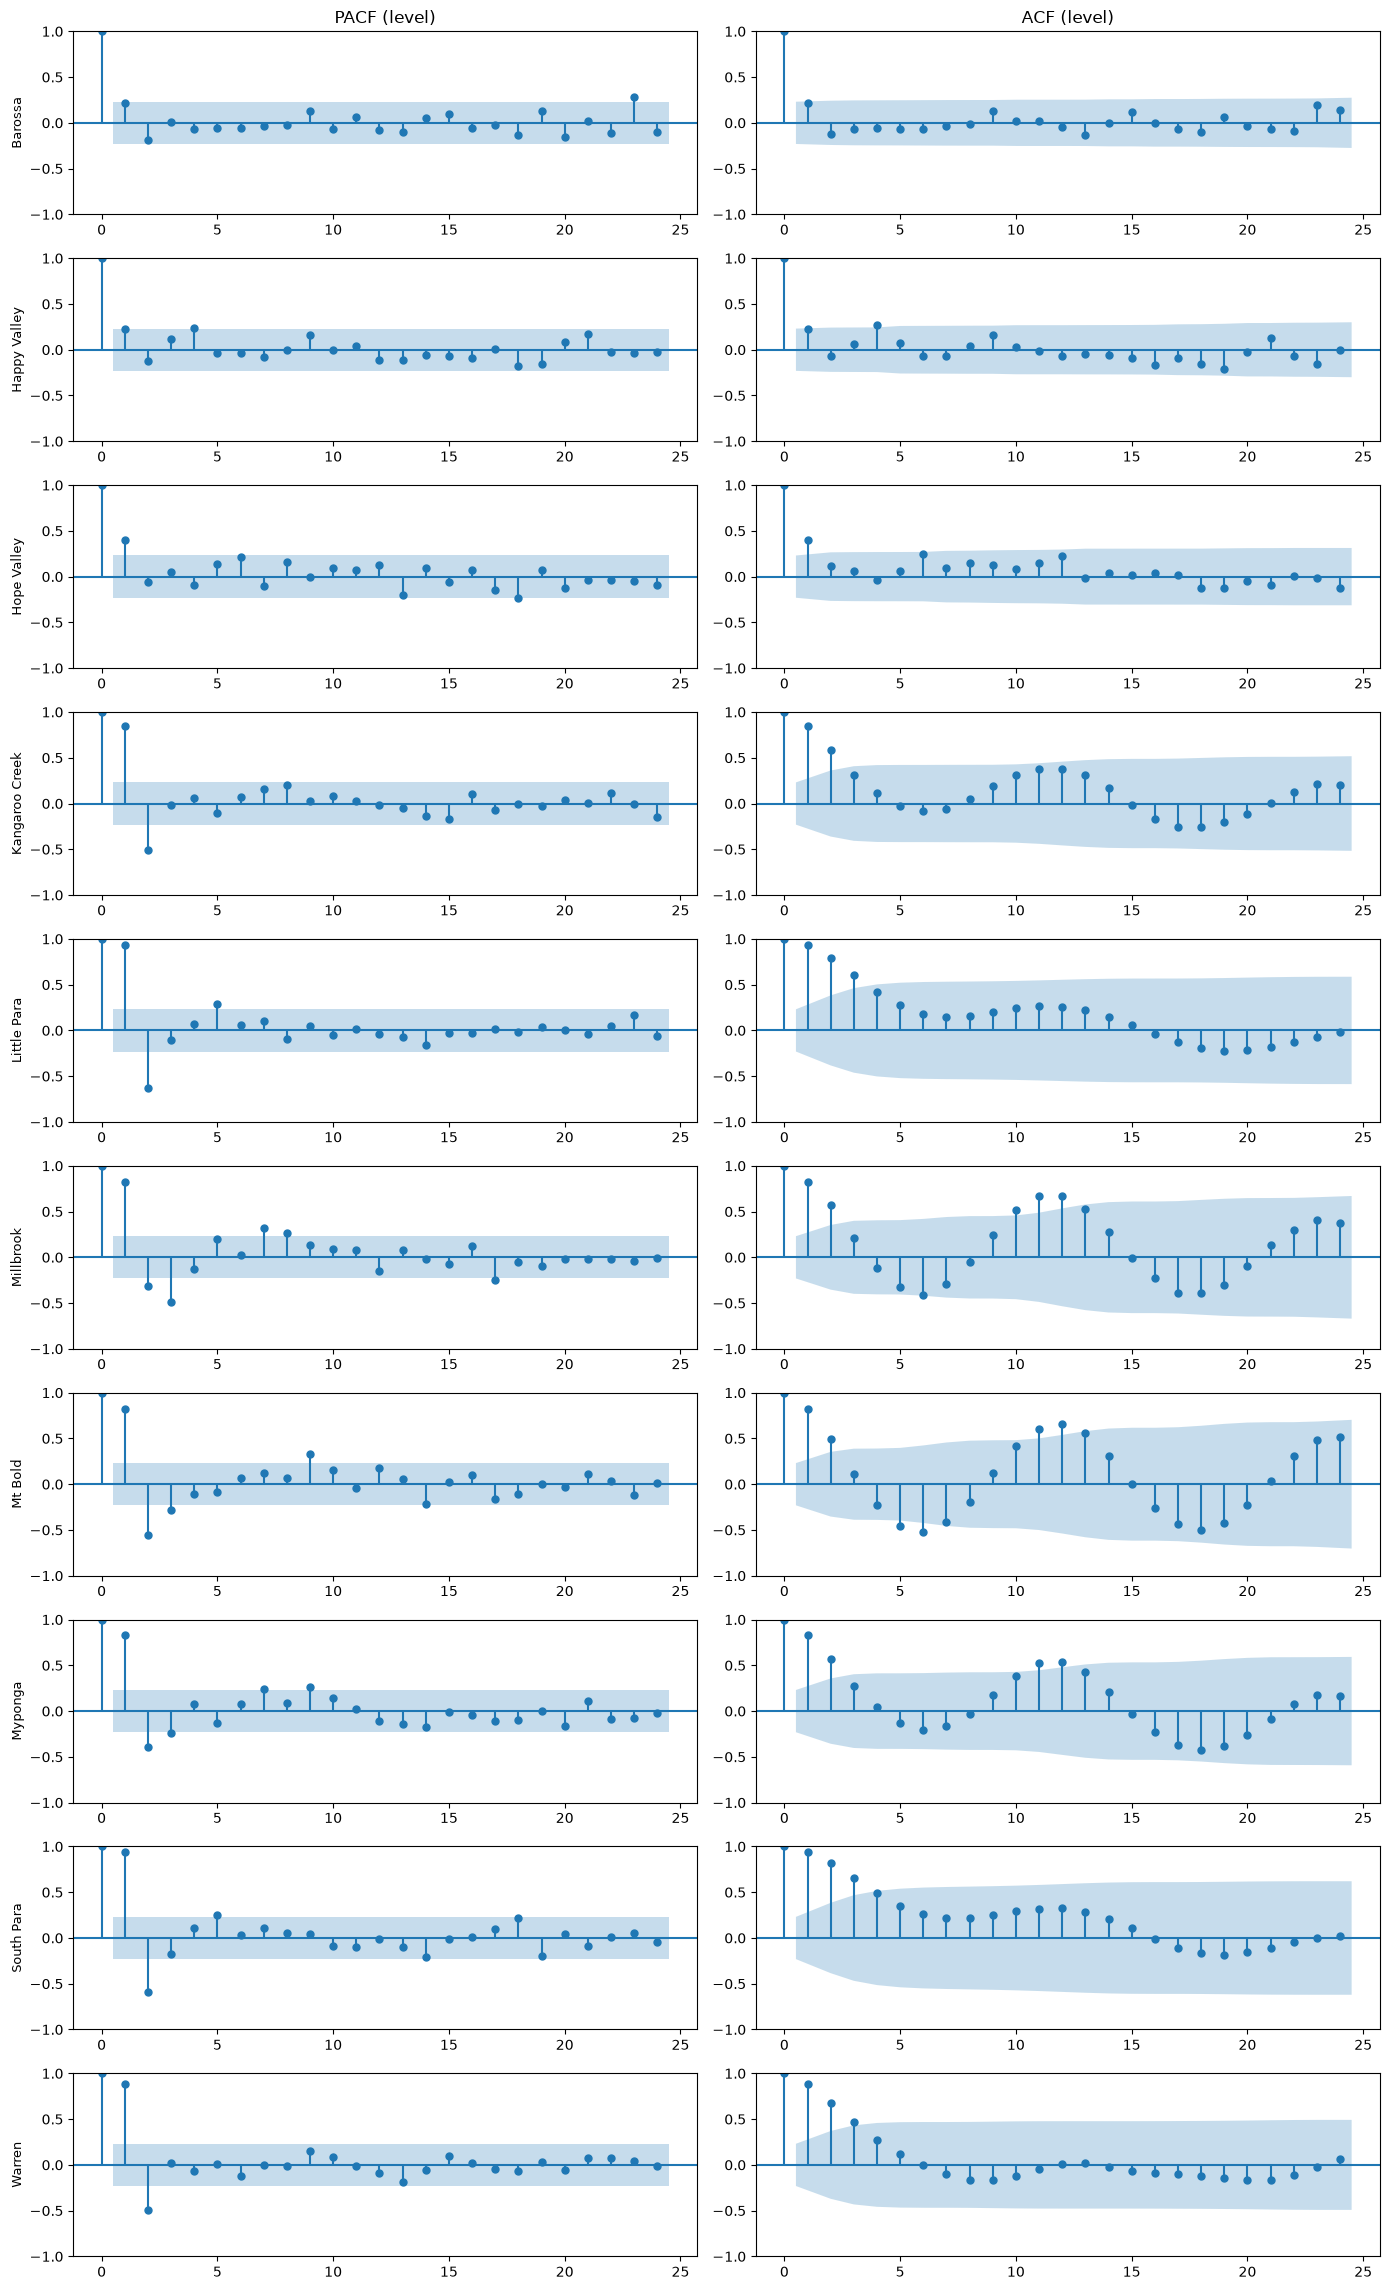

In [20]:
fig, axes = plt.subplots(len(RESERVOIRS), 2, figsize=(14, 2.3 * len(RESERVOIRS)))
for row, name in zip(axes, RESERVOIRS):
    s = df.loc[(df["reservoir"] == name) & train_months, "frac_full"].to_numpy()
    plot_pacf(s, lags=24, ax=row[0], title=None, method="ywm")  # level
    plot_acf(s, lags=24, ax=row[1], title=None)                 # level
    row[0].set_ylabel(name.replace(" Reservoir", ""), fontsize=9)
for ax, title in zip(axes[0], ["PACF (level)", "ACF (level)"]):
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 3. Seasonal cycle

A clear, shared shape justifies the month encoding and makes seasonal naive a meaningful baseline. Reservoirs with a flat or unusual shape are likely driven by human operations rather than the season.

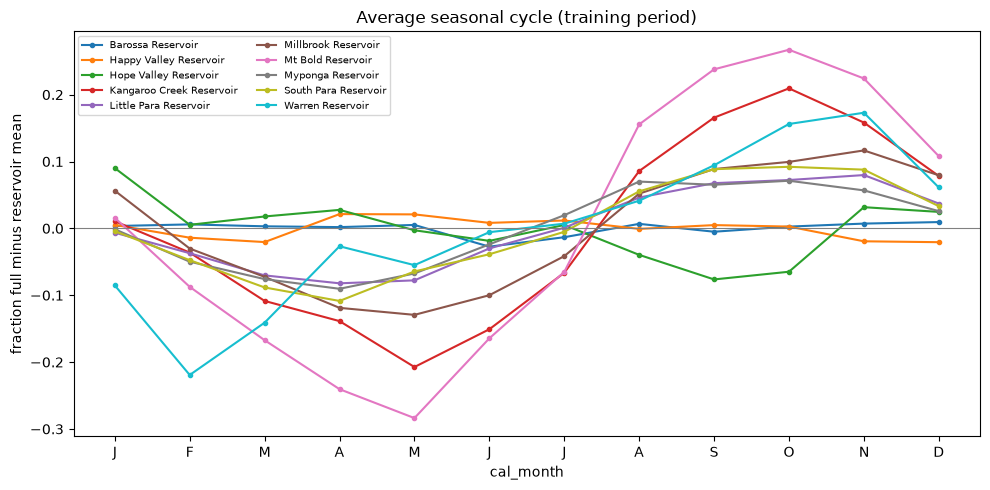

reservoir
Barossa Reservoir           0.037
Happy Valley Reservoir      0.042
Myponga Reservoir           0.162
Little Para Reservoir       0.162
Hope Valley Reservoir       0.167
South Para Reservoir        0.201
Millbrook Reservoir         0.246
Warren Reservoir            0.392
Kangaroo Creek Reservoir    0.417
Mt Bold Reservoir           0.551
Name: seasonal swing (fraction), dtype: float64

In [21]:
seasonal = (df[train_months]
            .assign(cal_month=lambda d: d["month"].dt.month)
            .pivot_table(index="cal_month", columns="reservoir", values="frac_full", aggfunc="mean"))

# Subtract each reservoir's own mean so the shapes are comparable
(seasonal - seasonal.mean()).plot(figsize=(10, 5), marker=".")
plt.axhline(0, color="0.5", lw=0.8)
plt.xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
plt.ylabel("fraction full minus reservoir mean")
plt.title("Average seasonal cycle (training period)")
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

# Size of the seasonal swing per reservoir (peak month minus trough month)
(seasonal.max() - seasonal.min()).sort_values().round(3).rename("seasonal swing (fraction)")

## Rainfall

Correlation between rainfall in month *t* and the change in volume from *t* to *t+1*

Low values show reservoirs whose volume may be fed by human operations rather than rain.

Same-month rainfall vs same-month change is **not** usable as an input (it isn't known at the forecast origin how much it will rain in the next month).

In [22]:
df["next_change"] = df.groupby("reservoir")["frac_full"].shift(-1) - df["frac_full"]   # t -> t+1
df["this_change"] = df.groupby("reservoir")["frac_full"].diff()                        # t-1 -> t

rain_link = (df[train_months]
             .groupby("reservoir")
             .apply(lambda g: pd.Series({
                 "corr(rain_t, change t->t+1)": g["rain_mm"].corr(g["next_change"]),
             }))
             .round(2)
             .sort_values("corr(rain_t, change t->t+1)"))
rain_link

,"corr(rain_t, change t->t+1)"
reservoir,
Happy Valley Reservoir,-0.12
Hope Valley Reservoir,-0.10
Warren Reservoir,-0.10
Barossa Reservoir,-0.02
Millbrook Reservoir,0.44
South Para Reservoir,0.47
Myponga Reservoir,0.48
Mt Bold Reservoir,0.49
Kangaroo Creek Reservoir,0.50


## Training Set

### Distribution

Look at range and skew of input features in the training set.

`frac_full` is already mostly between 0 and 1, so it may need no further scaling.

       frac_full  yoy_frac  rain_mm
count    720.000   720.000  720.000
mean       0.676     0.000   54.395
std        0.239     0.177   41.402
min        0.004    -0.994    0.000
25%        0.493    -0.063   20.600
50%        0.749     0.000   45.300
75%        0.872     0.073   79.725
max        1.063     0.907  203.400

skew: {'frac_full': -0.57, 'yoy_frac': -0.55, 'rain_mm': 0.82}


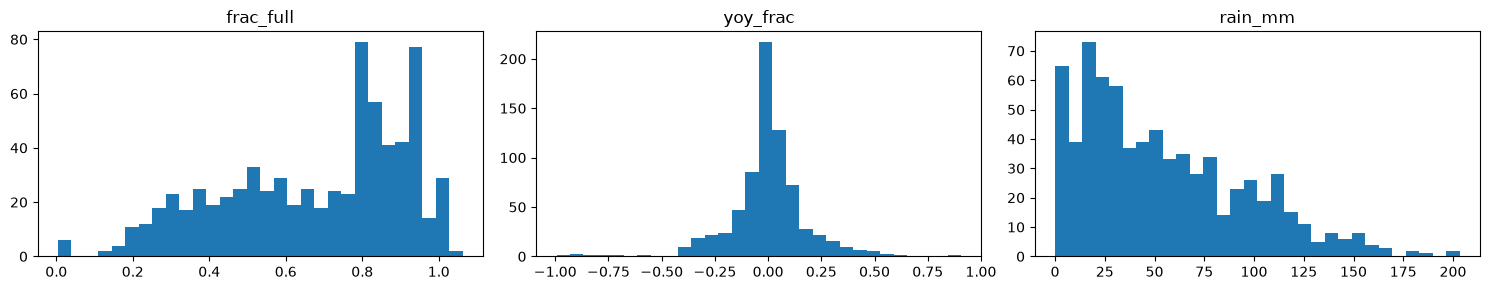

In [23]:
inputs = ["frac_full", "yoy_frac", "rain_mm"]
train_rows = df[df["split"].isin(["input only", "train"])]

print(train_rows[inputs].describe().round(3))
print("\nskew:", train_rows[inputs].skew().round(2).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, col in zip(axes, inputs):
    ax.hist(train_rows[col], bins=30)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Compared to test set

If test-period volumes sit outside the training range, forecasting models must extrapolate, which some are better at than others.

In [24]:
by_split = (df[df["split"].isin(["train", "val", "test"])]
            .groupby(["reservoir", "split"])["frac_full"]
            .agg(["min", "max"]).unstack("split").round(2))

# Flag reservoirs whose test range goes beyond their train range
by_split["test below train"] = by_split[("min", "test")] < by_split[("min", "train")]
by_split["test above train"] = by_split[("max", "test")] > by_split[("max", "train")]
by_split

min               max             test below train test above train
split                     test train   val  test train   val                                  
reservoir                                                                                     
Barossa Reservoir         0.91  0.87  0.91  0.96  0.95  0.94            False             True
Happy Valley Reservoir    0.81  0.78  0.80  0.95  1.00  0.91            False            False
Hope Valley Reservoir     0.71  0.45  0.58  0.90  0.97  0.98            False            False
Kangaroo Creek Reservoir  0.37  0.15  0.12  1.01  1.01  0.36            False            False
Little Para Reservoir     0.47  0.27  0.18  0.74  0.80  0.43            False            False
Millbrook Reservoir       0.54  0.47  0.44  0.91  0.96  0.67            False            False
Mt Bold Reservoir         0.31  0.00  0.21  0.94  0.94  0.56            False            False
Myponga Reservoir         0.47  0.66  0.49  0.94  0.99  0.70             True            False
South Para Reservoir      0.33  0.26  0.28  0.81  0.99  0.50            False            False
Warren Reservoir          0.30  0.01  0.33  0.71  1.06  0.77            False            False

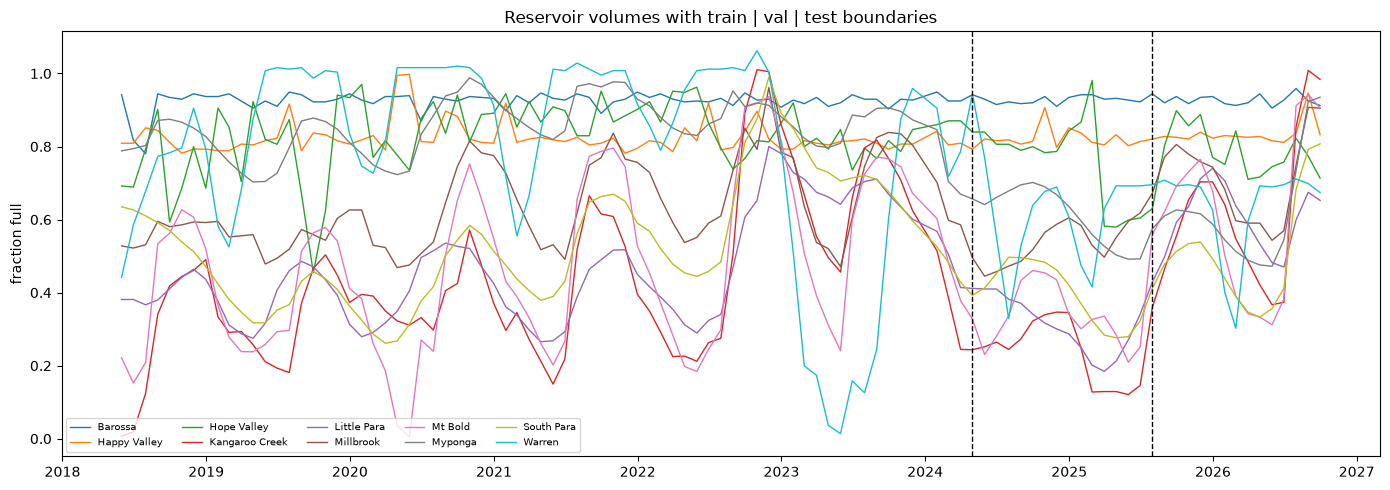

In [25]:
# The whole picture: fraction full over time with the split boundaries marked
fig, ax = plt.subplots(figsize=(14, 5))
for name in RESERVOIRS:
    g = df[df["reservoir"] == name]
    ax.plot(g["month"], g["frac_full"], lw=1, label=name.replace(" Reservoir", ""))
for boundary in (train_end, val_end):
    ax.axvline(boundary, color="black", ls="--", lw=1)
ax.set_ylabel("fraction full")
ax.set_title("Reservoir volumes with train | val | test boundaries")
ax.legend(fontsize=7, ncol=5, loc="lower left")
plt.tight_layout()
plt.show()

### Outliers

Values that could distort training judged against each reservoir's own typical variation (e.g. 10% monthly change is normal for Mt Bold but extreme for Barossa.)

In [28]:
MAD_TO_SD = 1 / 0.6745   # about 1.4826, scaling MAD to equal the standard deviation for normal data

def robust_z(s):
    """Robust z-score: distance from the median in units of (scaled) median absolute deviation."""
    mad = (s - s.median()).abs().median()
    return (s - s.median()) / (MAD_TO_SD * mad) if mad > 0 else s * 0

df["change"] = df.groupby("reservoir")["frac_full"].diff()                   # t-1 -> t
df["change_z"] = df.groupby("reservoir")["change"].transform(robust_z)       # vs that reservoir's own changes
df["rain_z"] = df.groupby("station")["rain_mm"].transform(robust_z)

# Extreme levels: nearly empty, or above capacity
extreme_level = (df["frac_full"] < 0.10) | (df["frac_full"] > 1.0)

# Extreme month-to-month changes
extreme_change = df["change_z"].abs() > 3.5

# Spikes
next_change = df.groupby("reservoir")["change"].shift(-1)
spike = extreme_change & (np.sign(next_change) == -np.sign(df["change"])) & (next_change.abs() > 0.5 * df["change"].abs())

# 4. Extreme rainfall months
extreme_rain = df["rain_z"] > 3.5

outliers = df.assign(extreme_level=extreme_level, extreme_change=extreme_change,
                     spike=spike, extreme_rain=extreme_rain)
flag_cols = ["extreme_level", "extreme_change", "spike", "extreme_rain"]

# Counts per reservoir and per split: how much of each kind, and is it in train, val or test?
print(outliers.groupby("reservoir")[flag_cols].sum())
print()
order = ["input only", "train", "val", "test"]
g = outliers.groupby("split")[flag_cols]
by_split = g.sum().reindex(order).astype(str) + " (" + (g.mean() * 100).round(1).reindex(order).astype(str) + "%)"
by_split.insert(0, "rows", outliers.groupby("split").size().reindex(order))
print(by_split)

                          extreme_level  extreme_change  spike  extreme_rain
reservoir                                                                   
Barossa Reservoir                     0               2      0             0
Happy Valley Reservoir                0              14      5             0
Hope Valley Reservoir                 0               3      0             1
Kangaroo Creek Reservoir              5               3      0             0
Little Para Reservoir                 0               1      0             0
Millbrook Reservoir                   0               0      0             0
Mt Bold Reservoir                     2               5      0             0
Myponga Reservoir                     0               5      0             0
South Para Reservoir                  0               4      0             0
Warren Reservoir                     28               2      0             0

            rows extreme_level extreme_change     spike extreme_rain
split 

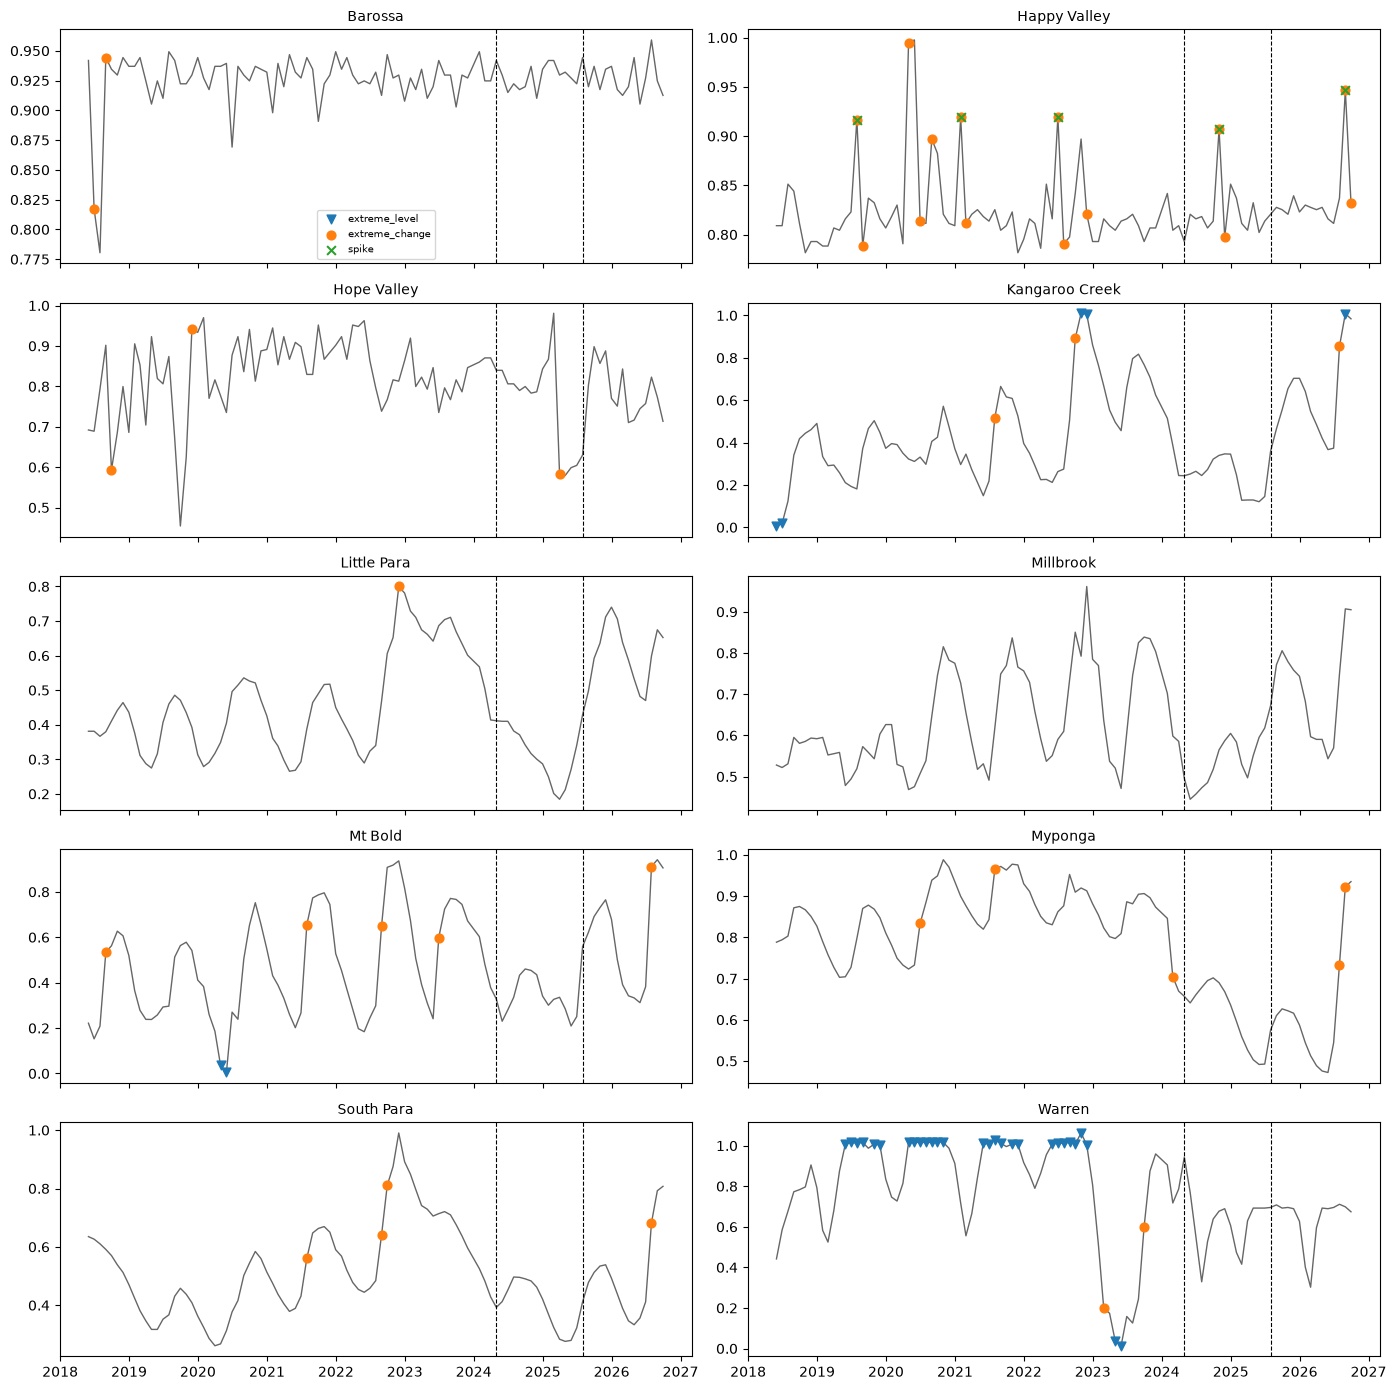

In [30]:
# Flagged months marked on each reservoir's series: is it an isolated point, or a sustained episode?
fig, axes = plt.subplots(5, 2, figsize=(14, 14), sharex=True)
for ax, name in zip(axes.flat, RESERVOIRS):
    g = outliers[outliers["reservoir"] == name]
    ax.plot(g["month"], g["frac_full"], lw=1, color="0.4")
    for col, marker in [("extreme_level", "v"), ("extreme_change", "o"), ("spike", "x")]:
        pts = g[g[col]]
        ax.scatter(pts["month"], pts["frac_full"], marker=marker, s=40, label=col, zorder=3)
    for boundary in (train_end, val_end):
        ax.axvline(boundary, color="black", ls="--", lw=0.8)
    ax.set_title(name.replace(" Reservoir", ""), fontsize=10)
axes.flat[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

#### Follow-Up: Happy Valley

In [31]:
#Happy Valley
flagged[flagged["spike"]][["reservoir", "month", "split", "frac_full", "change", "volume_source"]]

,reservoir,month,split,frac_full,change,volume_source
115,Happy Valley Reservoir,2019-07-31,train,0.916681,0.093722,observed
133,Happy Valley Reservoir,2021-01-31,train,0.919156,0.110132,observed
150,Happy Valley Reservoir,2022-06-30,train,0.919156,0.103180,observed
178,Happy Valley Reservoir,2024-10-31,val,0.906820,0.093165,observed
200,Happy Valley Reservoir,2026-08-31,test,0.946609,0.109585,observed


## Findings
Used to inform `features.py` and `splits.py`

- Limitations to note in Report regarding Test set rainfall measures:
    - 4.3% imputed by `clean.py`, not from actual data
    - 48.6% `Quality = N` (not quality-controlled yet.) Might be worth going back after quality controls are implemented for most recent data to see if it alters project findings.
- Interpolated volumes (December 2023) are in train only, and recovered volumes make up 20% of validation but are accurate readings based on findings from `EDA_interim.ipynb`

- PACF at lag 1 is strong (0.82-0.94) for 7/10 reservoirs. Lag 2 is strongly negative for most, and lag 3 is only significant for 3/10 reservoirs. This leads to the conclusion that a good default lag before it's fine-tuned is 2

- Some reservoirs (Kangaroo Creek, Little Para, Millbrook, Mt Bold, Myponga, South Para) have large seasonal swings and strong rainfall correlation across a common shared cycle, whereas others (Barossa, Happy Valley, Hope Valley) do not. Because of this difference, it's important to keep one-hot encoding of the reservoir as an input feature and report metrics per reservoir.

-  The min-max range of the test set is covered by train + validation. But the validation set is in a drought (forecasts will be validated against a period of decline). Because of this, it'll be important to refit on train + validation after fine-tuning.

- All outliers reflect real patterns and trends, so they're kept. Happy Valley specifically has five one-month spikes of about +10% reaching similar - but not the exact same - levels, indicating they're not just stale values. 
